# Tuned lens для LLaDA-8B-Instruct

Диффузионный вариант tuned lens (`tuned_lens_diffusion`). Для 50 текстов WikiText сэмплер LLaDA строит траектории расшумления (общая длина 128 токенов, по две случайные длины промпта из 16, 32, …, 112 на текст). Снимки делятся на 4 бина по доле замаскированных токенов ответа, из каждого бина берётся 250 снимков (всего 1000). Переводчики слоёв обучаются одним проходом SGD (lr 1.0, момент 0.9, weight decay 1e-3) по KL с финальным распределением модели только на замаскированных позициях; линзы бинов объединяются в одну.

Ноутбук запускается из папки `tuned-lens/`; веса сохраняются в `diffusion-tuned_lens/train_lenses/GSAI-ML/LLaDA-8B-Instruct`, где их ищут `evaluation_baselines.ipynb` и `global_workspace_experiments-parallel.ipynb`.


In [1]:
import os
import sys
import json
import gc
import time
from pathlib import Path

sys.path.append("./diffusion-tuned_lens/")

import random
import numpy as np
import torch
from tqdm import tqdm

In [2]:
from tuned_lens_diffusion import (
    DiffusionTunedLens,
    build_corpus,
    evaluate,
    lens_logits,
    load_llada,
    resolve_mask_token_id,
    train_bins,
)
from jlens.examples import load_wikitext_prompts

from datasets import Dataset, load_dataset
import matplotlib.pyplot as plt

In [3]:
MODEL_NAME = "GSAI-ML/LLaDA-8B-Instruct"
PRECISION = "bfloat16"
DEVICE = "cuda:0"
SEED = 42

OUTPUT_DIR = Path("./diffusion-tuned_lens/train_lenses") / MODEL_NAME
os.makedirs(OUTPUT_DIR, exist_ok=True)

EVAL_OUTPUT_DIR = Path("./diffusion-tuned_lens/eval_lenses") / MODEL_NAME
os.makedirs(EVAL_OUTPUT_DIR, exist_ok=True)

DATA_SOURCE_PATH = Path("./diffusion-tuned_lens/data.jsonl")

In [4]:
LR = 1.0
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
N_EPOCHS = 1

DATA_SOURCE = "wikitext"
MAX_SEQ_LEN = 128
n_prompts = 1_000
N_COLLECT_PROMPTS = 50

TOTAL_LEN = MAX_SEQ_LEN
PROMPT_LENS = list(range(16, TOTAL_LEN, 16))
N_PROMPT_LENS_PER_TEXT = 2
N_BINS = 4
SAMPLE_SEED = SEED

MAX_TRAIN_SNAPSHOTS = 1000

In [5]:
device = torch.device(DEVICE)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [6]:
match DATA_SOURCE:
    case "wikitext":
        prompts = load_wikitext_prompts(n_prompts=n_prompts)
        records = [{"text": p} for p in prompts]

    case "pile":
        pile = load_dataset("EleutherAI/the_pile", split="validation", streaming=True)
        records = [{"text": doc["text"]} for doc in pile]

    case _:
        raise ValueError(f"get {DATA_SOURCE}")

with DATA_SOURCE_PATH.open("w") as f:
    for r in tqdm(records):
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

100%|██████████| 1000/1000 [00:00<00:00, 57796.67it/s]


In [7]:
hf_model, tokenizer = load_llada(MODEL_NAME, device=DEVICE, dtype=getattr(torch, PRECISION))
mask_id = resolve_mask_token_id(hf_model)
print(f"mask_id={mask_id} | n_layers={hf_model.config.n_layers} | d_model={hf_model.config.d_model}")

Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

mask_id=126336 | n_layers=32 | d_model=4096


проверка параметров для train

In [8]:
raw_ds = Dataset.from_json(str(DATA_SOURCE_PATH))
prompts_text = raw_ds["text"][:N_COLLECT_PROMPTS]

n_variants_per_text = (
    min(N_PROMPT_LENS_PER_TEXT, len(PROMPT_LENS))
    if N_PROMPT_LENS_PER_TEXT is not None
    else len(PROMPT_LENS)
)
variants = len(prompts_text) * n_variants_per_text

snapshots_per_variant = sum(TOTAL_LEN - p - 1 for p in PROMPT_LENS) / len(PROMPT_LENS)
expected_snapshots = int(variants * snapshots_per_variant)
n_train = expected_snapshots if MAX_TRAIN_SNAPSHOTS is None else min(expected_snapshots, MAX_TRAIN_SNAPSHOTS)

print(f"текстов в data.jsonl:         {len(raw_ds)}")
print(f"текстов в корпусе:            {len(prompts_text)}")
print(f"вариантов (text, prompt_len): {variants} ({n_variants_per_text} на текст)")
print(f"ожидаемо снапшотов:           ~{expected_snapshots:,}")
print(f"снапшотов на обучение:        {n_train:,} (MAX_TRAIN_SNAPSHOTS={MAX_TRAIN_SNAPSHOTS})")
print(f"tau-бинов:                    {N_BINS}")

if n_train == 0:
    print("[FAIL] снапшотов нет — увеличьте N_COLLECT_PROMPTS/PROMPT_LENS.")
else:
    print("[OK] корпус непустой. Сбор — самый дорогой шаг: уменьшите "
          "N_COLLECT_PROMPTS или PROMPT_LENS, если долго.")

Generating train split: 0 examples [00:00, ? examples/s]

текстов в data.jsonl:         1000
текстов в корпусе:            50
вариантов (text, prompt_len): 100 (2 на текст)
ожидаемо снапшотов:           ~6,300
снапшотов на обучение:        1,000 (MAX_TRAIN_SNAPSHOTS=1000)
tau-бинов:                    4
[OK] корпус непустой. Сбор — самый дорогой шаг: уменьшите N_COLLECT_PROMPTS или PROMPT_LENS, если долго.


сбор диффузионного корпуса

In [9]:
examples, tau_bins = build_corpus(
    hf_model, tokenizer, prompts_text, device=DEVICE, mask_id=mask_id,
    total_len=TOTAL_LEN, prompt_lens=PROMPT_LENS,
    n_prompt_lens_per_text=N_PROMPT_LENS_PER_TEXT, sample_seed=SAMPLE_SEED,
    n_bins=N_BINS,
)
print(f"собрано {len(examples)} снапшотов; "
      f"бины: { {b: tau_bins.count(b) for b in sorted(set(tau_bins))} }")

if MAX_TRAIN_SNAPSHOTS is not None and len(examples) > MAX_TRAIN_SNAPSHOTS:
    rng = random.Random(SEED)
    by_bin = {}
    for i, b in enumerate(tau_bins):
        by_bin.setdefault(b, []).append(i)
    per_bin = max(1, MAX_TRAIN_SNAPSHOTS // len(by_bin))
    keep = sorted(i for idx in by_bin.values() for i in rng.sample(idx, min(per_bin, len(idx))))
    examples = [examples[i] for i in keep]
    tau_bins = [tau_bins[i] for i in keep]
    print(f"подвыборка до {len(examples)} снапшотов; бины: "
          f"{ {b: tau_bins.count(b) for b in sorted(set(tau_bins))} }")

build_diffusion_examples: варианты (text, prompt_len):   0%|          | 0/100 [00:00<?, ?it/s]

собрано 6380 снапшотов; бины: {0: 1520, 1: 1620, 2: 1620, 3: 1620}
подвыборка до 1000 снапшотов; бины: {0: 250, 1: 250, 2: 250, 3: 250}


train

In [12]:
bin_lenses = train_bins(
    hf_model, examples, tau_bins, mask_id=mask_id, device=DEVICE,
    lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY,
)

lens = DiffusionTunedLens.merge(list(bin_lenses.values()))
print(f"merged: {lens.config.n_prompts} снапшотов, layers={lens.config.num_hidden_layers}")

lens.save(OUTPUT_DIR)
print("сохранено в", OUTPUT_DIR)

del bin_lenses
gc.collect()
torch.cuda.empty_cache()

100%|██████████| 4/4 [04:14<00:00, 63.70s/it]


eval

In [10]:
lens = DiffusionTunedLens.load(OUTPUT_DIR, hf_model=hf_model)

metrics = evaluate(hf_model, lens, examples, mask_id=mask_id, device=DEVICE)
with (EVAL_OUTPUT_DIR / "aggregate_metrics.json").open("w") as f:
    json.dump(metrics, f, indent=2)

100%|██████████| 1000/1000 [07:01<00:00,  2.37it/s]


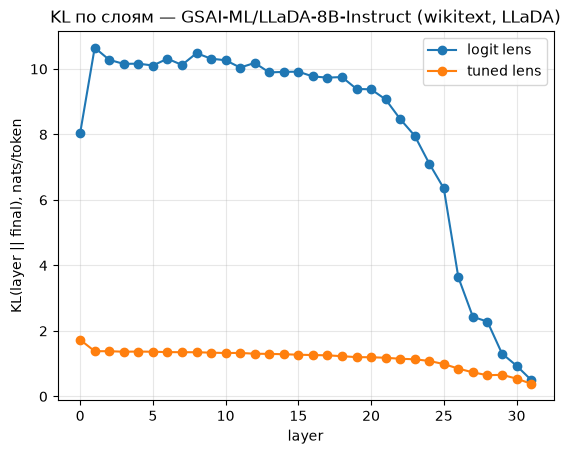

In [11]:
agg = json.load(open(EVAL_OUTPUT_DIR / "aggregate_metrics.json"))
layers = list(range(len(agg["tuned"]["kl"])))

for name in ["logit", "tuned"]:
    plt.plot(layers, agg[name]["kl"], marker="o", label=f"{name} lens")

plt.xlabel("layer")
plt.ylabel("KL(layer || final), nats/token")
plt.title(f"KL по слоям — {MODEL_NAME} ({DATA_SOURCE}, LLaDA)")
plt.legend()
plt.grid(alpha=.3);

inference

In [13]:
prompt = "The capital of France is"
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
mask_col = torch.full((1, 1), mask_id, dtype=input_ids.dtype, device=device)
input_ids = torch.cat([input_ids, mask_col], dim=1)

layer = 20
lens_logits_dict, model_logits, _ = lens_logits(
    hf_model, lens, input_ids=input_ids, positions=[-1], device=DEVICE,
)
print("layer", layer, "->", repr(tokenizer.decode([lens_logits_dict[layer][0].argmax().item()])))
print("final      ->", repr(tokenizer.decode([model_logits[0].argmax().item()])))

layer 20 -> ' in'
final      -> ' Paris'
